In [1]:
#Paso 1: Preparar el notebook
%load_ext autoreload
%autoreload 2

import io

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import median_filter
from sklearn.metrics import roc_auc_score
from scipy.ndimage import binary_dilation
from scipy.ndimage import find_objects, label

from fraude_recibos import config

FINDIT_DIR = config.FINDIT_DIR


def cargar_canonica(ruta):
    """Representación única para todo el proyecto: escala de grises, sin alfa."""
    with Image.open(FINDIT_DIR / ruta) as img:
        if img.mode in ("RGBA", "LA"):
            fondo = Image.new("RGBA", img.size, (255, 255, 255, 255))
            img = Image.alpha_composite(fondo, img.convert("RGBA"))
        return np.array(img.convert("L"))


metadata = pd.read_parquet(config.PROCESSED_DIR / "metadata.parquet")
regiones = pd.read_parquet(config.PROCESSED_DIR / "regiones.parquet")

# Misma definición de zona alterada que en la Fase 2
regiones["alterada"] = (~regiones["area_original"]) & (regiones["tecnica"] != "None")
regiones["tecnica_principal"] = regiones["tecnica"].str.split(",").str[0]

reg_train = regiones[(regiones["split"] == "train") & regiones["alterada"]].copy()
rutas = metadata.set_index("id")["ruta_imagen"]

print("Zonas alteradas en entrenamiento:", len(reg_train))
print(reg_train["tecnica_principal"].value_counts())

Zonas alteradas en entrenamiento: 272
tecnica_principal
CPI      199
CUT       27
PIX       21
IMI       19
CPO        5
Autre      1
Name: count, dtype: int64


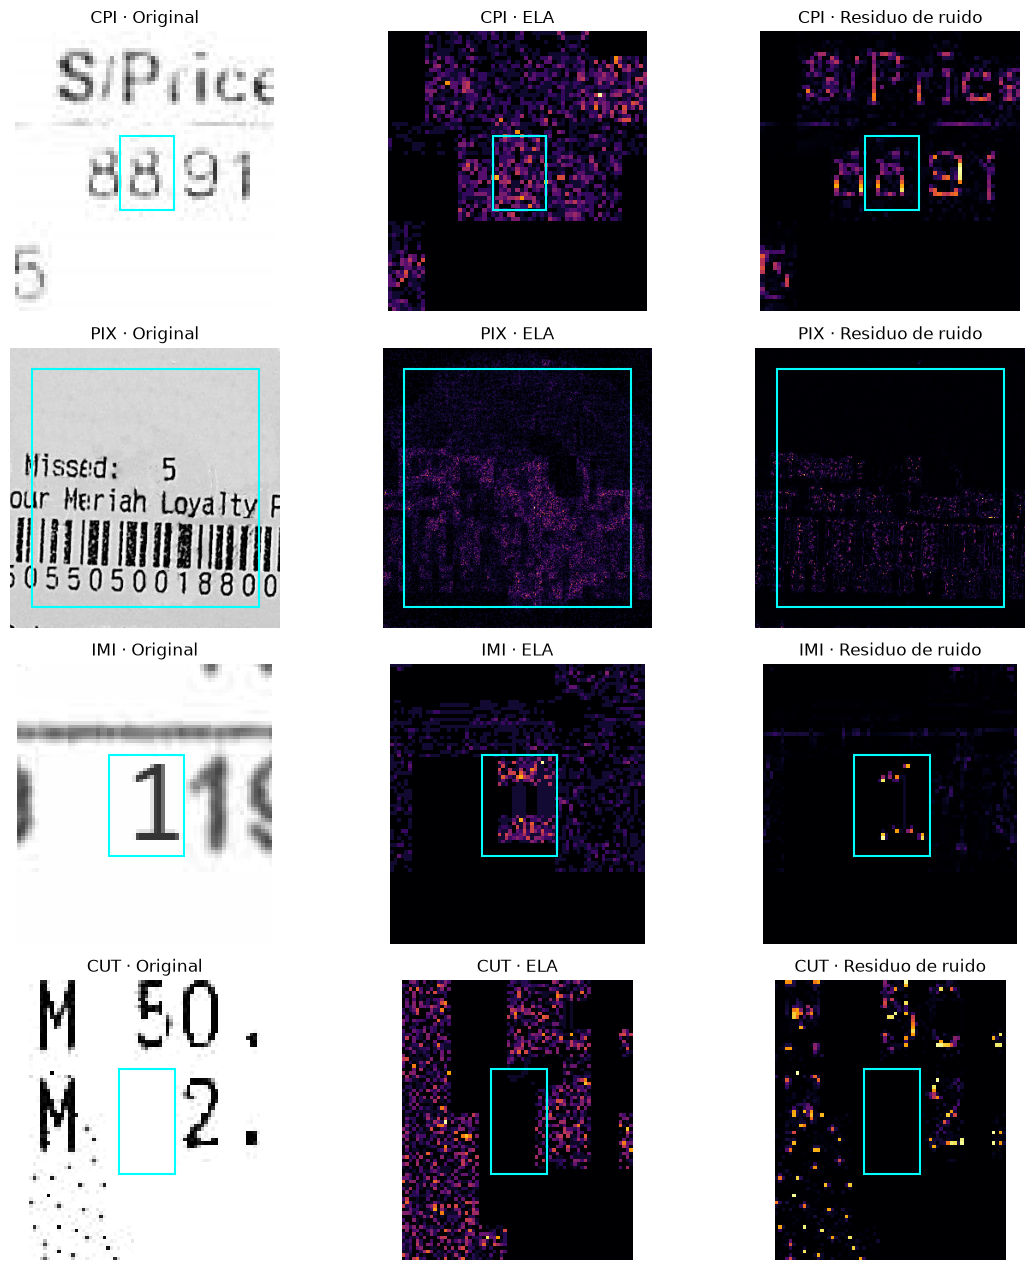

In [2]:
#Paso 2: Mirar las alteraciones
def ela(gris, calidad=90):
    """Error Level Analysis: diferencia entre la imagen y su recompresión JPEG."""
    buffer = io.BytesIO()
    Image.fromarray(gris).save(buffer, "JPEG", quality=calidad)
    buffer.seek(0)
    recomprimida = np.array(Image.open(buffer))
    return np.abs(gris.astype(np.int16) - recomprimida.astype(np.int16)).astype(np.uint8)


def residuo_ruido(gris):
    """Grano del escáner: diferencia entre la imagen y su versión suavizada."""
    suavizada = median_filter(gris, size=3)
    return np.abs(gris.astype(np.int16) - suavizada.astype(np.int16)).astype(np.uint8)


def recorte(imagen, r, margen=25):
    y0, x0 = max(r.y - margen, 0), max(r.x - margen, 0)
    y1 = min(r.y + r.alto + margen, imagen.shape[0])
    x1 = min(r.x + r.ancho + margen, imagen.shape[1])
    return imagen[y0:y1, x0:x1], (r.x - x0, r.y - y0)


tecnicas = ["CPI", "PIX", "IMI", "CUT"]
fig, axes = plt.subplots(len(tecnicas), 3, figsize=(12, 3.2 * len(tecnicas)))

for fila_ax, tecnica in zip(axes, tecnicas):
    r = reg_train[reg_train["tecnica_principal"] == tecnica].iloc[0]
    gris = cargar_canonica(rutas[r.id])
    paneles = {"Original": gris, "ELA": ela(gris), "Residuo de ruido": residuo_ruido(gris)}

    for ax, (titulo, panel) in zip(fila_ax, paneles.items()):
        trozo, (rx, ry) = recorte(panel, r)
        if titulo == "Original":
            ax.imshow(trozo, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(trozo, cmap="inferno", vmin=0, vmax=max(int(trozo.max()), 1))
        ax.add_patch(patches.Rectangle((rx, ry), r.ancho, r.alto, edgecolor="cyan", facecolor="none", linewidth=1.5))
        ax.set_title(f"{tecnica} · {titulo}")
        ax.axis("off")

plt.tight_layout()
fig.savefig(config.REPORTS_DIR / "forense_ejemplos.png", dpi=120, bbox_inches="tight")
plt.show()

In [3]:
#Paso 3: Medir con ventaja (análisis oráculo)
def estadisticas_zona(gris, mapa_ela, mapa_ruido, x, y, w, h):
    zona = gris[y:y + h, x:x + w]
    tinta = zona < 200
    trazos = binary_dilation(tinta, iterations=1)  # trazos más un píxel de borde
    ela_zona = mapa_ela[y:y + h, x:x + w]
    ruido_zona = mapa_ruido[y:y + h, x:x + w]
    return {
        "ela_media": float(ela_zona.mean()),
        "ruido_medio": float(ruido_zona.mean()),
        "niveles_distintos": int(len(np.unique(zona))),
        "pct_puros": float(np.isin(zona, [0, 255]).mean() * 100),
        "pct_tinta": float(tinta.mean() * 100),
        "ela_trazos": float(ela_zona[trazos].mean()) if trazos.any() else np.nan,
        "ruido_trazos": float(ruido_zona[trazos].mean()) if trazos.any() else np.nan,
    }


def solapa(x, y, w, h, otras):
    return any(
        x < o.x + o.ancho and o.x < x + w and y < o.y + o.alto and o.y < y + h
        for o in otras.itertuples()
    )


filas = []
for id_recibo, grupo in reg_train.groupby("id"):
    gris = cargar_canonica(rutas[id_recibo])
    mapa_ela, mapa_ruido = ela(gris), residuo_ruido(gris)
    anotadas = regiones[regiones["id"] == id_recibo]  # incluye zonas de origen de copias

    for r in grupo.itertuples():
        base = {"id": id_recibo, "tecnica": r.tecnica_principal}
        filas.append({**base, "tipo": "alterada",
                      **estadisticas_zona(gris, mapa_ela, mapa_ruido, r.x, r.y, r.ancho, r.alto)})

        for factor in (1.5, -1.5, 3, -3):
            cx = int(r.x + factor * r.ancho)
            if cx < 0 or cx + r.ancho > gris.shape[1]:
                continue
            if solapa(cx, r.y, r.ancho, r.alto, anotadas):
                continue
            if gris[r.y:r.y + r.alto, cx:cx + r.ancho].min() > 128:  # sin tinta
                continue
            filas.append({**base, "tipo": "control",
                          **estadisticas_zona(gris, mapa_ela, mapa_ruido, cx, r.y, r.ancho, r.alto)})
            break

zonas = pd.DataFrame(filas)
print(zonas.groupby(["tecnica", "tipo"]).size().unstack(fill_value=0), "\n")

estadisticos = ["ela_media", "ruido_medio", "niveles_distintos", "pct_puros",
                "pct_tinta", "ela_trazos", "ruido_trazos"]


def auc_por_estadistico(df):
    resultado = {}
    for e in estadisticos:
        validos = df.dropna(subset=[e])
        y = (validos["tipo"] == "alterada").astype(int)
        resultado[e] = roc_auc_score(y, validos[e]) if y.nunique() == 2 else np.nan
    return resultado


tabla = {"Todas": auc_por_estadistico(zonas)}
for tecnica in tecnicas:
    sub = zonas[zonas["tecnica"] == tecnica]
    if sub["tipo"].nunique() == 2:
        tabla[tecnica] = auc_por_estadistico(sub)

pd.DataFrame(tabla).T.round(2)

tipo     alterada  control
tecnica                   
Autre           1        0
CPI           199      150
CPO             5        4
CUT            27       22
IMI            19       18
PIX            21       16 



,ela_media,ruido_medio,niveles_distintos,pct_puros,pct_tinta,ela_trazos,ruido_trazos
Todas,0.72,0.50,0.51,0.54,0.51,0.69,0.45
CPI,0.80,0.58,0.58,0.54,0.60,0.72,0.47
PIX,0.54,0.37,0.41,0.54,0.47,0.61,0.37
IMI,0.72,0.26,0.30,0.49,0.58,0.63,0.22
CUT,0.27,0.11,0.12,0.71,0.12,0.51,0.45


In [4]:
#Paso 4: Detección de copy-move
def componentes_duplicados(gris, umbral=160, area_min=20):
    """Grupos de caracteres con píxeles idénticos (posibles copias)."""
    tinta = gris < umbral
    etiquetas, _ = label(tinta)
    grupos = {}
    for i, sl in enumerate(find_objects(etiquetas), 1):
        if sl is None or (etiquetas[sl] == i).sum() < area_min:
            continue
        trozo = gris[sl]
        clave = (trozo.shape, trozo.tobytes())
        caja = (sl[1].start, sl[0].start, sl[1].stop - sl[1].start, sl[0].stop - sl[0].start)
        grupos.setdefault(clave, []).append(caja)
    return [cajas for cajas in grupos.values() if len(cajas) > 1]


ids_cpi = set(reg_train.loc[reg_train["tecnica"].str.contains("CPI"), "id"])
train_meta = metadata[metadata["split"] == "train"]

filas = []
for i, fila in enumerate(train_meta.itertuples(), 1):
    duplicados = componentes_duplicados(cargar_canonica(fila.ruta_imagen))
    filas.append({
        "id": fila.id,
        "forged": fila.forged,
        "tiene_cpi": fila.id in ids_cpi,
        "grupos_dup": len(duplicados),
        "comp_dup": sum(len(g) for g in duplicados),
        "cajas": duplicados,
    })
    if i % 100 == 0:
        print(f"{i}/{len(train_meta)}")

cm = pd.DataFrame(filas)
cm["categoria"] = np.select(
    [cm["forged"] == 0, cm["tiene_cpi"]],
    ["Auténtico", "Falsificado con CPI"],
    default="Falsificado sin CPI",
)

print("\n% de recibos con al menos un par de caracteres idénticos:")
print((cm.groupby("categoria")["grupos_dup"].apply(lambda s: (s > 0).mean() * 100)).round(1), "\n")

print(f"AUC (todos los falsificados): {roc_auc_score(cm['forged'], cm['comp_dup']):.2f}")
solo_cpi = cm[(cm["forged"] == 0) | cm["tiene_cpi"]]
print(f"AUC (auténticos vs. con CPI): {roc_auc_score(solo_cpi['forged'], solo_cpi['comp_dup']):.2f}")

100/575
200/575
300/575
400/575
500/575

% de recibos con al menos un par de caracteres idénticos:
categoria
Auténtico               0.4
Falsificado con CPI    81.1
Falsificado sin CPI    30.0
Name: grupos_dup, dtype: float64 

AUC (todos los falsificados): 0.85
AUC (auténticos vs. con CPI): 0.90


Recibos con CPI y duplicados detectados: 60
De ellos, los duplicados coinciden con una zona anotada en: 98.3 %


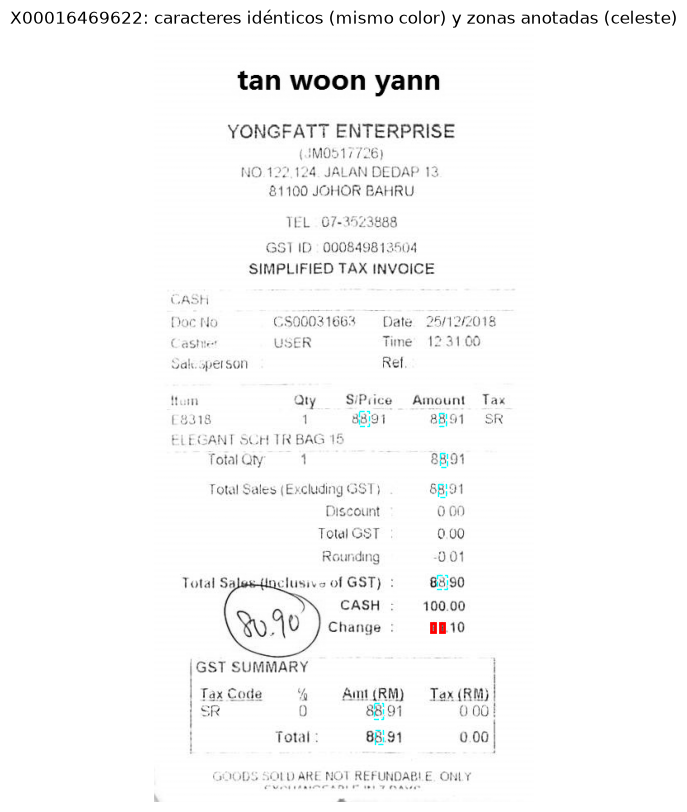

In [5]:
#Paso 5: ¿Apunta al lugar correcto?
def apunta_bien(fila):
    anotadas = regiones[regiones["id"] == fila.id]
    return any(solapa(x, y, w, h, anotadas) for grupo in fila.cajas for (x, y, w, h) in grupo)


detectados = cm[cm["tiene_cpi"] & (cm["grupos_dup"] > 0)]
print(f"Recibos con CPI y duplicados detectados: {len(detectados)}")
print(f"De ellos, los duplicados coinciden con una zona anotada en: {detectados.apply(apunta_bien, axis=1).mean() * 100:.1f} %")

# Ejemplo visual
ejemplo = detectados.iloc[0]
gris = cargar_canonica(rutas[ejemplo.id])
fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(gris, cmap="gray")
for grupo, color in zip(ejemplo.cajas, ["red", "blue", "green", "orange", "magenta"]):
    for x, y, w, h in grupo:
        ax.add_patch(patches.Rectangle((x, y), w, h, edgecolor=color, facecolor="none", linewidth=2))
for r in reg_train[reg_train["id"] == ejemplo.id].itertuples():
    ax.add_patch(patches.Rectangle((r.x, r.y), r.ancho, r.alto, edgecolor="cyan", facecolor="none", linewidth=1, linestyle="--"))
ax.set_title(f"{ejemplo.id}: caracteres idénticos (mismo color) y zonas anotadas (celeste)")
ax.axis("off")
fig.savefig(config.REPORTS_DIR / "copy_move_ejemplo.png", dpi=120, bbox_inches="tight")
plt.show()

               id  grupos_dup  comp_dup
5    X51005200938           3         8
152  X51005719862           2         7


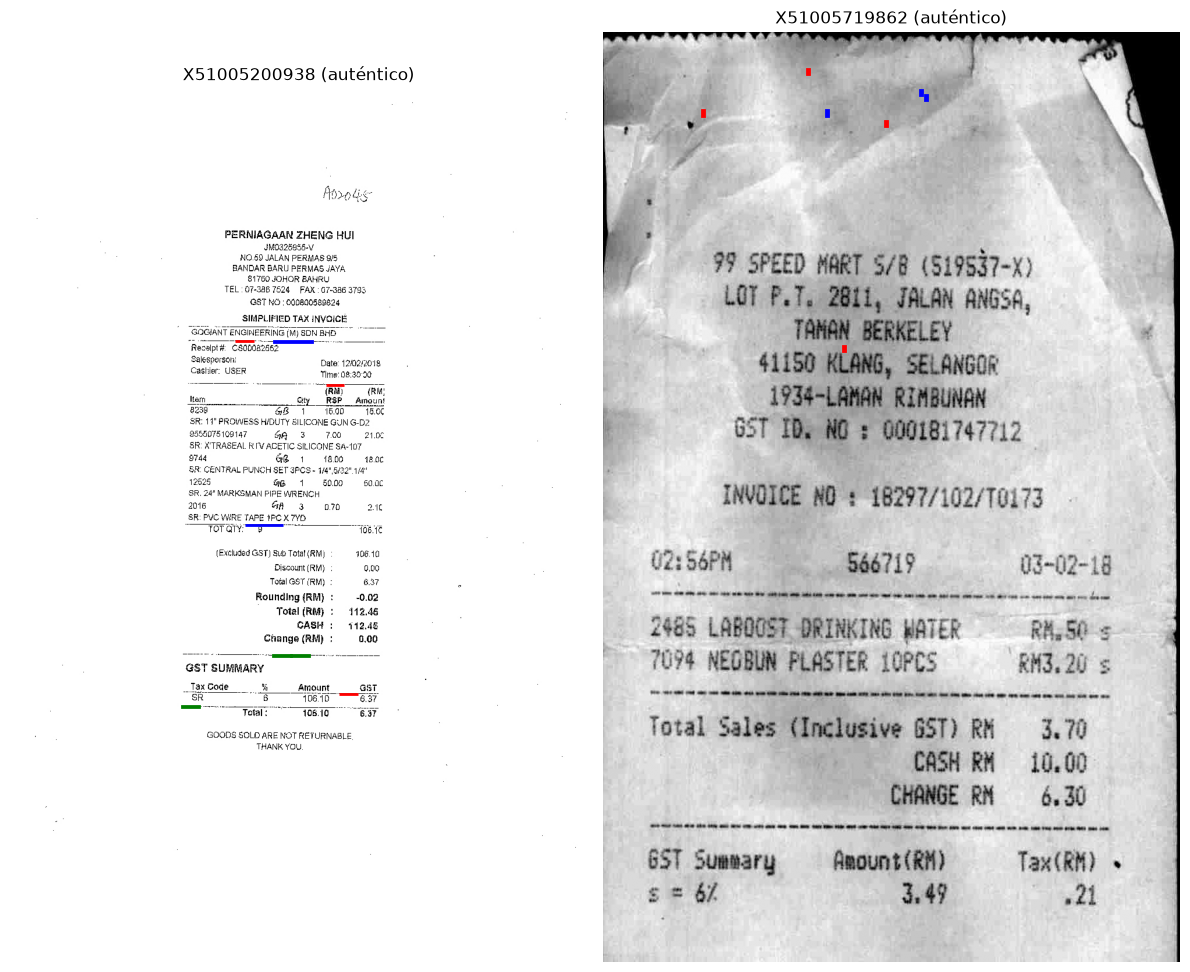

In [6]:
#Paso 6: Revisar las dos falsas alarmas
falsas_alarmas = cm[(cm["forged"] == 0) & (cm["grupos_dup"] > 0)]
print(falsas_alarmas[["id", "grupos_dup", "comp_dup"]])

fig, axes = plt.subplots(1, len(falsas_alarmas), figsize=(6 * len(falsas_alarmas), 10))
for ax, fila in zip(np.atleast_1d(axes), falsas_alarmas.itertuples()):
    gris = cargar_canonica(rutas[fila.id])
    ax.imshow(gris, cmap="gray")
    for grupo, color in zip(fila.cajas, ["red", "blue", "green", "orange", "magenta"]):
        for x, y, w, h in grupo:
            ax.add_patch(patches.Rectangle((x, y), w, h, edgecolor=color, facecolor="none", linewidth=2))
    ax.set_title(f"{fila.id} (auténtico)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusiones

**Análisis oráculo (zonas anotadas vs. controles vecinos).** Se identificaron tres señales
forenses genuinas, verificadas controlando la cantidad de tinta:
- ELA sobre trazos, más alto en zonas alteradas (AUC 0,72 en CPI): la copia desalinea los
  bloques JPEG heredados de los escaneos originales de SROIE.
- Ruido sobre trazos, más bajo en zonas imitadas (AUC 0,22 en IMI): los caracteres dibujados
  carecen del grano del escáner.
- Blanco puro, más alto en zonas borradas (AUC 0,71 en CUT).
La señal de ruido en CPI desapareció al controlar la tinta (0,58 → 0,47): era un artefacto.

**Copy-move por caracteres idénticos.** Detecta el 81 % de los recibos con CPI con solo
0,4 % de falsas alarmas (AUC 0,90), y en el 98 % de los casos señala una zona anotada.
Encontró además alteraciones no anotadas (ejemplo: el vuelto de X00016469622).

**Limitaciones.** El análisis oráculo es un mejor caso; en el recibo completo la señal se
diluirá. IMI, PIX y CUT tienen unas 20 zonas cada una. La detección exacta de copias depende
del formato PNG; se probará una variante tolerante y se medirá en la prueba de robustez.

**Implicancias para la Fase 5.** Variables forenses: máximo de ELA y mínimo de ruido sobre
trazos por zona de texto, porcentaje de blanco puro y número de caracteres duplicados.